# Multi-Coiled-Coil Designer

Design coiled-coil protein sequences from a short **architecture code**, fold them, and pick the best model.

All the machinery lives in **`mcc.py`** (next to this notebook) — you just edit the list in step 1 and run the cells top to bottom (`Run All`).

Prefer clicking to typing? Open **`mcc_builder.html`** in a browser for a visual version.


In [1]:
import mcc


## 1. Choose your architectures

Write each design as a code, one per line:

- **numbers** = helices in a module: `2`, `3`, `4` or `6`
- **`(n)`** between modules = helices shared with the next module: `1` or `2`
- a **`-`** in front of the first module makes it anticlockwise (default is clockwise)

Examples: `4(2)4`, `6(2)4(2)6`, `-4(2)4`, `3(2)4`


In [5]:
specs = [
    "-6", "6", "3(2)4", "-4(2)4", "4(2)4(2)4", "6(2)6", "6(2)4(2)6", "3(1)3", "3-(1)3"
]

mcc.save_fasta(specs, "mcc_sequences.fasta")


wrote 9 sequences -> mcc_sequences.fasta


'mcc_sequences.fasta'

## 2. Topology diagrams

Drawn with `topology_utils.py`. Each helix is a circle seen end-on: **blue** = you're looking down its N-terminus, **red** = its C-terminus. The chain's first and last helix are ringed (blue = sequence N-term, red = C-term). **Shape** = domain (hexagon=6, square=4, triangle=3, pair=2); lines are the loops.

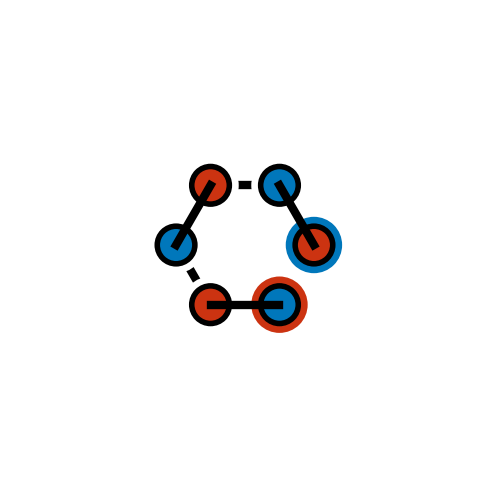

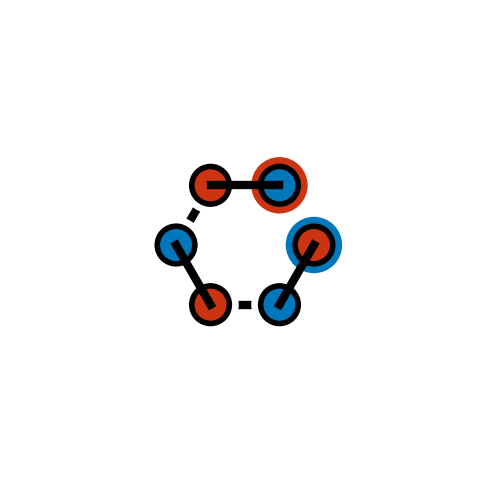

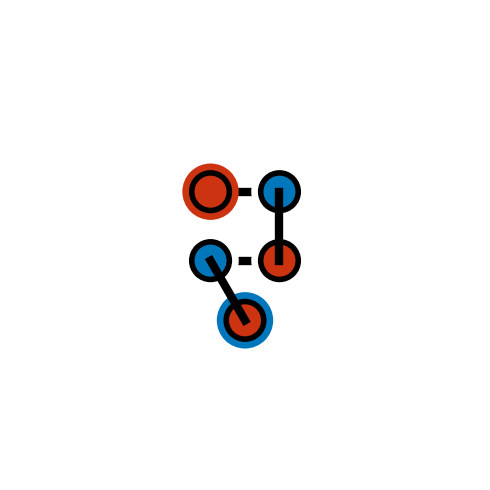

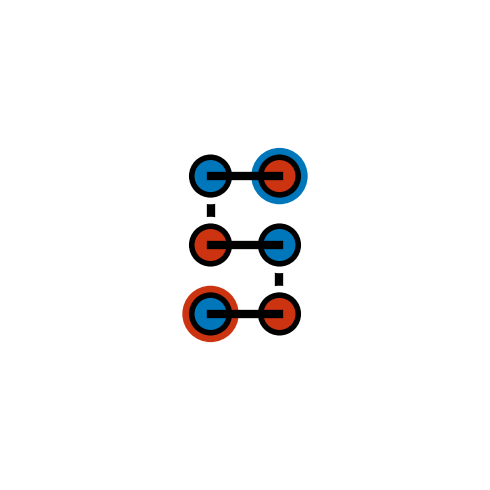

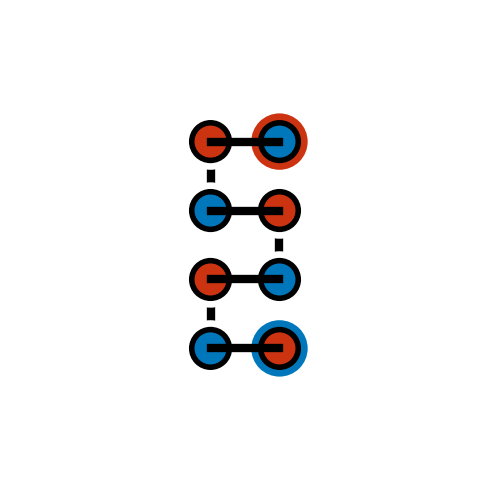

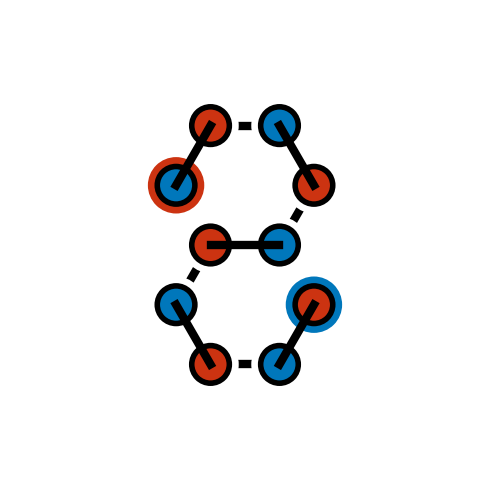

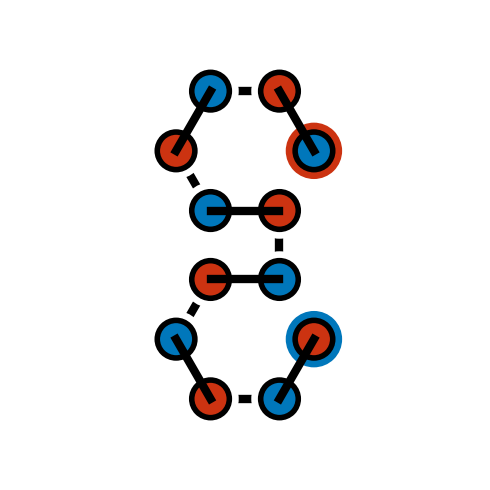

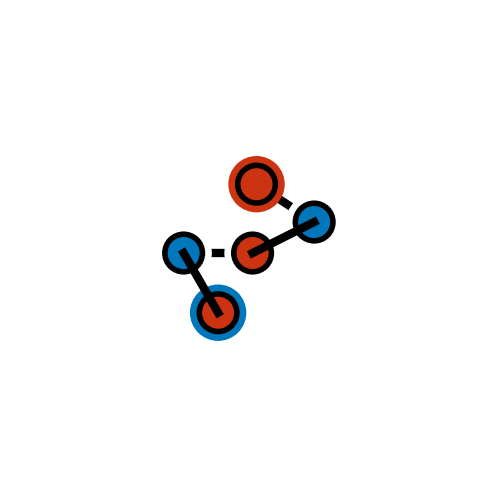

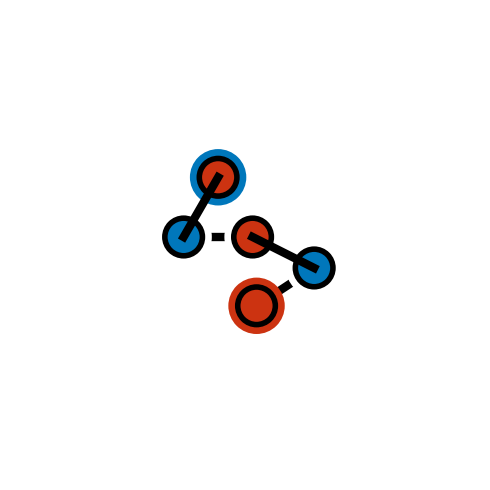

In [6]:
for s in specs:
    mcc.draw_topology(s)

## 3. Preview

A quick summary of each design (modules, loops, MASTER-mpnn `contigs`, and the sequence).


In [7]:
for s in specs:
    mcc.describe(s)
    print()


-6   (187 aa, 6 helices)
   modules : M1=6ACW
   loops   : dg ae dg ae dg
   contigs : A1-28/A34-61/A64-91/A97-124/A127-154/A160-187
   sequence: EEIAKLLEEIAKLLKKIAELLKKIAELLKKGGLEEIAKLLEEIAKLLKKIAELLKKIAELLGGEEIAKLLEEIAKLLKKIAELLKKIAELLKKGGLEEIAKLLEEIAKLLKKIAELLKKIAELLGGEEIAKLLEEIAKLLKKIAELLKKIAELLKKGGLEEIAKLLEEIAKLLKKIAELLKKIAELL

6   (184 aa, 6 helices)
   modules : M1=6CW
   loops   : ae dg ae dg ae
   contigs : A1-28/A31-58/A64-91/A94-121/A127-154/A157-184
   sequence: EEIAKLLEEIAKLLKKIAELLKKIAELLGGEEIAKLLEEIAKLLKKIAELLKKIAELLKKGGLEEIAKLLEEIAKLLKKIAELLKKIAELLGGEEIAKLLEEIAKLLKKIAELLKKIAELLKKGGLEEIAKLLEEIAKLLKKIAELLKKIAELLGGEEIAKLLEEIAKLLKKIAELLKKIAELL

3(2)4   (152 aa, 5 helices)
   modules : M1=3CW, M2=4CW
   loops   : ae dg link ae
   contigs : A1-28/A31-58/A64-91/A95-122/A125-152
   sequence: EELKQELEELKQELKKLKQELKKLKQELGGEILKQLLEILKQLLKILKQLLKILKQLLKKGGLEILKQLLEILKQLLKILKQLLKILKQLLKGGEEIAKQLEEIAKQLKKIAEQLKKIAEQLGGEEIAKQLEEIAKQLKKIAEQLKKIAEQL

-4(2)4   (185 aa, 6 helices)
   mod

## 4. Fold with ColabFold

Runs a **local** ColabFold on a Linux machine with a GPU ([localcolabfold](https://github.com/YoshitakaMo/localcolabfold) installed). It folds every sequence in the FASTA. This can take a while.

*(Skip this step if you just want sequences.)*


In [9]:
mcc.fold("mcc_sequences.fasta", "results")


running: /opt/localcolabfold/colabfold-conda/bin/colabfold_batch --msa-mode single_sequence mcc_sequences.fasta results
2026-07-08 07:53:49,527 Running colabfold 1.5.5 (fdf3b235b88746681c46ea12bcded76ecf8e1f76)


Traceback (most recent call last):
  File "/opt/localcolabfold/colabfold-conda/lib/python3.10/site-packages/colabfold/batch.py", line 1306, in run
    jax.tools.colab_tpu.setup_tpu()
  File "/opt/localcolabfold/colabfold-conda/lib/python3.10/site-packages/jax/tools/colab_tpu.py", line 20, in setup_tpu
    raise RuntimeError(
RuntimeError: jax.tools.colab_tpu.setup_tpu() was required for older JAX versions running on older generations of TPUs, and should no longer be used.

During handling of the above exception, another exception occurred:

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'
Traceback (most recent call last):
  File "/opt/localcolabfold/colabfold-conda/lib/python3.10/site-packages/colabfold/batch.py", line 1306, in run
    jax.tools.colab_tpu.setup_tpu()
  File "/opt/localcolabfold/colabfold-conda/lib/python3.10/site-packages/jax/tools/colab_tpu.py", line 20, in setup_tpu
    raise RuntimeError(
RuntimeError: jax.tools.colab_tpu.setup_tpu() was requ

2026-07-08 07:53:51,422 Running on GPU


2026-07-08 07:53:51.433819: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


2026-07-08 07:53:52,034 Found 2 citations for tools or databases
2026-07-08 07:53:52,035 Query 1/9: 3_2_4 (length 152)
2026-07-08 07:54:00,482 Padding length to 162
2026-07-08 07:54:46,367 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=88.4 pTM=0.803
2026-07-08 07:55:20,855 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=87.5 pTM=0.771 tol=0.399
2026-07-08 07:55:21,277 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=87.6 pTM=0.767 tol=0.0789
2026-07-08 07:55:21,698 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=87.6 pTM=0.767 tol=0.0591
2026-07-08 07:55:21,699 alphafold2_ptm_model_1_seed_000 took 81.2s (3 recycles)
2026-07-08 07:55:22,155 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=84.7 pTM=0.742
2026-07-08 07:55:22,584 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=88.2 pTM=0.794 tol=0.508
2026-07-08 07:55:23,010 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=89.1 pTM=0.807 tol=0.0898
2026-07-08 07:55:23,438 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=89.2 pTM=0.809 tol=0.

## 5. View the models and save your favourite

Pick a sequence and one of its 5 models, view it coloured by confidence (blue = high, red = low), then **⭐ Save this model** to copy it into a `selected/` folder.


In [10]:
mcc.view_models("results")


---
**Advanced:** open `mcc.py` to retune the chemistry (`seq_lib`, `loop_lib`) or the offset/handedness rules. The 1-shared-helix sign is still a placeholder (`ONE_SHARED_DEFAULT`).
